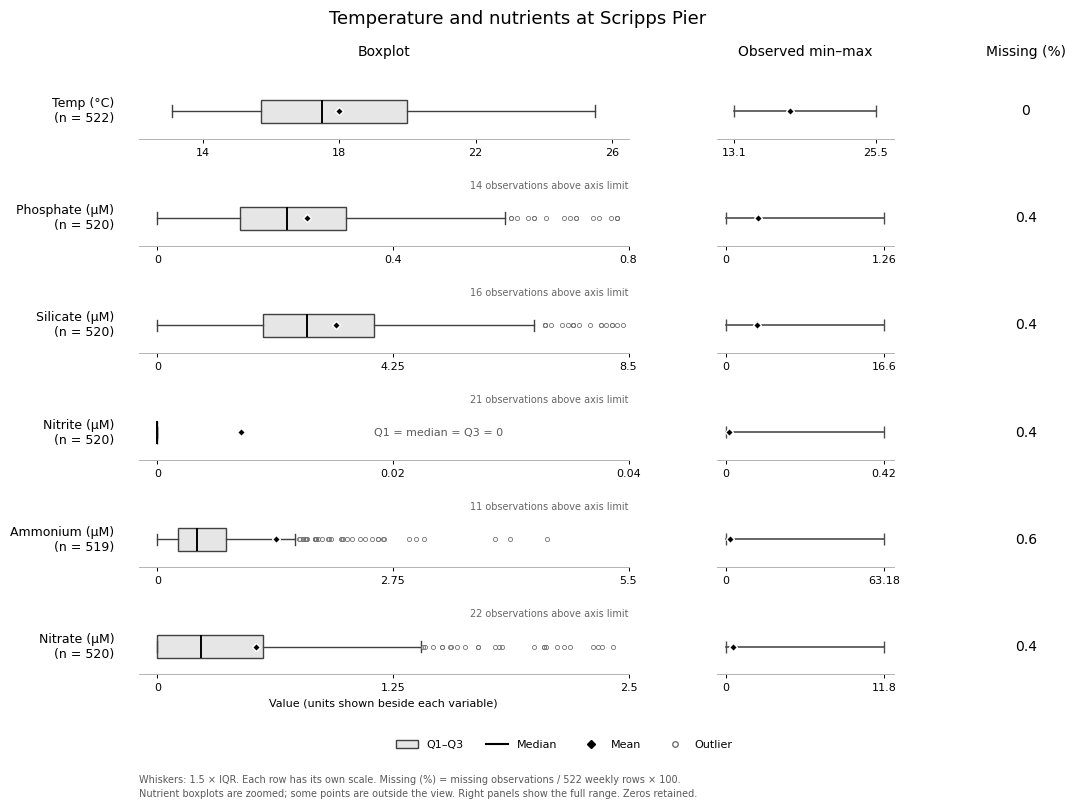

 Variable   n  Missing count  Missing (%)
     Temp 522              0          0.0
Phosphate 520              2          0.4
 Silicate 520              2          0.4
  Nitrite 520              2          0.4
 Ammonium 519              3          0.6
  Nitrate 520              2          0.4
Saved: C:\Users\ASUS\nutrient_boxplots_simple.png


In [1]:
"""Temperature/nutrient boxplots with missing percentages. Edit FILE, then run.
Requires: pandas, openpyxl and matplotlib >= 3.10.
"""
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

FILE = "HABs_ScrippsPier_v3 (2).xlsx"
SHEET = "Sheet1"
OUTPUT = "nutrient_boxplots_simple.png"
FULL_VIEW = False  # True: show all outliers; False: zoom the left panels.

NAMES = ["Temp", "Phosphate", "Silicate", "Nitrite", "Ammonium", "Nitrate"]
ZOOM_MAX = [28, 0.8, 8.5, 0.04, 5.5, 2.5]


def make_plot(file=FILE, sheet=SHEET, output=OUTPUT, full_view=FULL_VIEW):
    raw = pd.read_excel(file, sheet_name=sheet, engine="openpyxl")
    raw.columns = raw.columns.astype(str).str.strip()
    missing = [name for name in NAMES if name not in raw.columns]
    if missing:
        raise ValueError(f"Missing columns: {missing}")
    # The original Sheet1 has a units row immediately below its headers.
    # Remove only that row BEFORE calculating the weekly-row denominator.
    # This also supports a cleaned sheet that has no units row.
    if len(raw) and str(raw.iloc[0]["Temp"]).strip().lower() in {"degree_c", "degc", "°c"}:
        raw = raw.iloc[1:].copy()
    numeric = raw[NAMES].apply(pd.to_numeric, errors="coerce")
    total = len(numeric)
    if total == 0:
        raise ValueError("No weekly observations found.")
    missing_count = numeric.isna().sum()
    missing_pct = missing_count / total * 100
    # Exclude missing values only from the plotted statistics; retain zeros.
    data = [numeric[name].dropna() for name in NAMES]
    if any(s.empty for s in data):
        raise ValueError("Each nutrient must contain numeric observations.")

    with plt.rc_context({"font.family": "sans-serif", "font.size": 9,
                         "axes.linewidth": 0.7, "xtick.major.width": 0.7}):
        fig, axes = plt.subplots(6, 3, figsize=(11.5, 8.2),
                                 gridspec_kw={"width_ratios": [3.6, 1.3, 0.65]})
        fig.subplots_adjust(left=0.17, right=0.98, top=0.89, bottom=0.17,
                            hspace=0.95, wspace=0.35)
        fig.suptitle("Temperature and nutrients at Scripps Pier", fontsize=13, y=0.98)
        axes[0, 0].set_title("Boxplot",
                             fontsize=10, pad=20)
        axes[0, 1].set_title("Observed min–max", fontsize=10, pad=20)
        axes[0, 2].set_title("Missing (%)", fontsize=10, pad=20)

        for i, (name, s) in enumerate(zip(NAMES, data)):
            ax, rng, missing_ax = axes[i]
            q1, median, q3 = s.quantile([0.25, 0.5, 0.75])
            lo, hi, mean = s.min(), s.max(), s.mean()
            limit = max(hi * 1.05, 0.01) if full_view else ZOOM_MAX[i]
            ax.boxplot(s, orientation="horizontal", positions=[1], widths=0.5,
                       whis=1.5, autorange=False, patch_artist=True,
                       showmeans=True, showfliers=True,
                       boxprops=dict(facecolor="0.90", edgecolor="0.25", linewidth=1),
                       medianprops=dict(color="black", linewidth=1.4),
                       whiskerprops=dict(color="0.25", linewidth=1),
                       capprops=dict(color="0.25", linewidth=1),
                       meanprops=dict(marker="D", markerfacecolor="black",
                                      markeredgecolor="white", markersize=4),
                       flierprops=dict(marker="o", markerfacecolor="none",
                                       markeredgecolor="0.45", markersize=3,
                                       markeredgewidth=0.6))
            if name == "Temp":
                padding = max(hi - lo, 0.1) * 0.08
                ax.set_xlim(lo - padding, hi + padding)
                ticks = [14, 18, 22, 26]
            else:
                ax.set_xlim(-limit * 0.04, limit)
                ticks = [0, limit / 2, limit]
            ax.set_xticks(ticks, labels=[f"{x:.3g}" for x in ticks])
            unit = "°C" if name == "Temp" else "µM"
            ax.text(-0.05, 0.5, f"{name} ({unit})\n(n = {len(s)})", transform=ax.transAxes,
                    ha="right", va="center", fontsize=9)
            off_axis = int((s > ax.get_xlim()[1]).sum())
            if off_axis:
                ax.text(1, 1.04, f"{off_axis} observations above axis limit",
                        transform=ax.transAxes, ha="right", fontsize=7, color="0.4")
            if q1 == median == q3 == 0:
                ax.text(0.48, 0.5, "Q1 = median = Q3 = 0", fontsize=8,
                        transform=ax.transAxes, va="center", color="0.35")

            rng.plot([lo, hi], [1, 1], color="0.3", linewidth=1.2,
                     marker="|", markersize=9)
            rng.plot(mean, 1, marker="D", color="black", markersize=4,
                     markeredgecolor="white")
            pad = max(hi - lo, abs(hi), 0.01) * 0.06
            rng.set_xlim(lo - pad, hi + pad)
            ticks = [lo, hi] if lo != hi else [lo]
            rng.set_xticks(ticks, labels=[f"{x:g}" for x in ticks])
            for a in (ax, rng):
                a.set_ylim(0.4, 1.6)
                a.set_yticks([])
                for side in ("top", "right", "left"):
                    a.spines[side].set_visible(False)
                a.spines["bottom"].set_color("0.7")
                a.tick_params(axis="x", labelsize=8, length=3)

            missing_ax.set_axis_off()
            missing_label = f"{missing_pct[name]:.1f}".rstrip("0").rstrip(".")
            missing_ax.text(0.5, 0.5, missing_label, ha="center", va="center",
                            transform=missing_ax.transAxes, fontsize=10)

        axes[-1, 0].set_xlabel("Value (units shown beside each variable)", fontsize=8)
        legend = [Patch(facecolor="0.9", edgecolor="0.25", label="Q1–Q3"),
                  Line2D([], [], color="black", label="Median"),
                  Line2D([], [], color="black", marker="D", linestyle="none",
                         markersize=4, label="Mean"),
                  Line2D([], [], color="0.45", marker="o", markerfacecolor="none",
                         linestyle="none", markersize=4, label="Outlier")]
        fig.legend(handles=legend, loc="lower center", bbox_to_anchor=(0.54, 0.065),
                   ncol=4, frameon=False, fontsize=8)
        note = f"Whiskers: 1.5 × IQR. Each row has its own scale. Missing (%) = missing observations / {total} weekly rows × 100."
        if not full_view:
            note += "\nNutrient boxplots are zoomed; some points are outside the view. Right panels show the full range. Zeros retained."
        fig.text(0.17, 0.02, note, fontsize=7, color="0.35", linespacing=1.5)
        output = Path(output)
        output.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(output, dpi=300, facecolor="white")
        plt.show()
        plt.close(fig)
        summary = pd.DataFrame({"Variable": NAMES, "n": [len(s) for s in data],
                                "Missing count": missing_count.to_numpy(),
                                "Missing (%)": missing_pct.round(1).to_numpy()})
        print(summary.to_string(index=False))
        print(f"Saved: {output.resolve()}")
        return output


# Works in a notebook cell or as a .py file; no argparse/kernel -f conflict.
if __name__ == "__main__":
    make_plot()
